## PyTorch Computer Vision 

**torchvision** --> Contains datasets, model architectures and image transformations often used for computer vision problems.

**torchvision.datasets** --> Here you'll find many example computer vision datasets for a range of problems from image classification, object detection, image captioning, video classification and more. It also contains a series of base classes for making custom datasets.

**torchvision.models** -->	This module contains well-performing and commonly used computer vision model architectures implemented in PyTorch, you can use these with your own problems.

**torchvision.transforms** -->	Often images need to be transformed (turned into numbers/processed/augmented) before being used with a model, common image transformations are found here.

**torch.utils.data.Dataset** --> Base dataset class for PyTorch.
**torch.utils.data.DataLoader** -->	Creates a Python iterable over a dataset (created with torch.utils.data.Dataset).

**ToTensor** --> Converts a PIL Image or numpy.ndarray (H x W x C) in the range [0, 255] to a torch.FloatTensor of shape (C x H x W) in the range [0.0, 1.0] if the PIL Image belongs to one of the modes (L, LA, P, I, F, RGB, YCbCr, RGBA, CMYK, 1) or if the numpy.ndarray has dtype = np.uint8

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset
from torchmetrics import ConfusionMatrix

from mlxtend.plotting import plot_confusion_matrix

import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor


from helper_functions import accuracy_fn


import matplotlib.pyplot as plt 
import pandas as pd
import requests

from tqdm.auto import tqdm ## for progress bar

from pathlib import Path

print(torch.__version__)
print(torchvision.__version__)

2.14.1+cu130
0.29.1+cu130


In [2]:
## Download helper functions from Learn PyTorch repo

if Path("helper_functions.py").is_file():
    print("helper_functions.py already exists, skipping download...")

else:
    print("Download helper_functions.py")

    request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")

    with open("helper_functions.py", "wb") as f:
        f.write(requests.content)

helper_functions.py already exists, skipping download...


### Getting a Dataset

The dataset we'll be using is FashionMINIST from `torchvision.datasets`



In [3]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform= ToTensor(),
    target_transform=None
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

In [4]:
len(train_data), len(test_data)

(60000, 10000)

In [5]:
class_name = test_data.classes

print("Class\n", class_name)



Class
 ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [6]:
## Check Image Shape 
image , lable = train_data[0]
print("Image Shape: ", image.shape)
print("Image labels: ", class_name[lable])

Image Shape:  torch.Size([1, 28, 28])
Image labels:  Ankle boot


### Visualizing Data 



(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

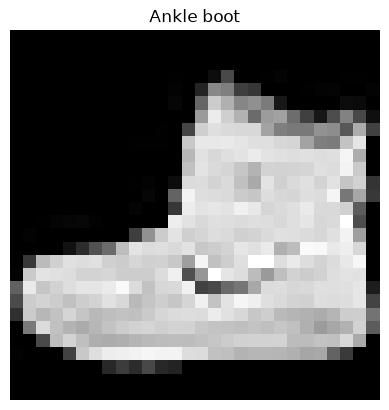

In [7]:
image, lable = train_data[0]
plt.imshow(image.squeeze(), cmap="gray")
plt.title(class_name[lable])
plt.axis(False)

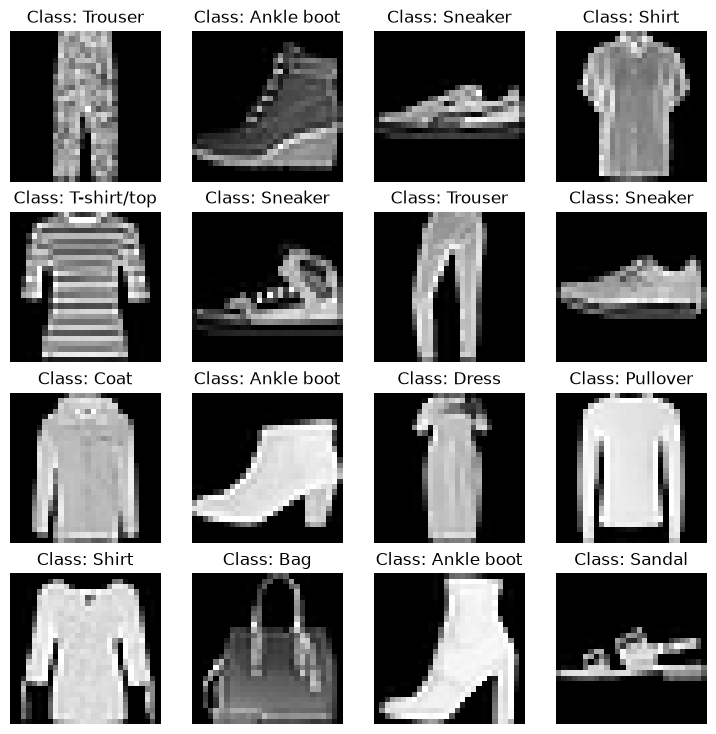

In [8]:
# Visualize More Image


torch.manual_seed(42)
fig = plt.figure(figsize=(9,9))

rows, cols = 4, 4

for i in range(1, rows*cols+1):
    random_index = torch.randint(0, len(test_data), size=[1]).item()
    image, label= train_data[random_index]

    fig.add_subplot(rows, cols, i)

    plt.imshow(image.squeeze(), cmap="gray")

    plt.title(f"Class: {class_name[label]}")

    plt.axis(False);

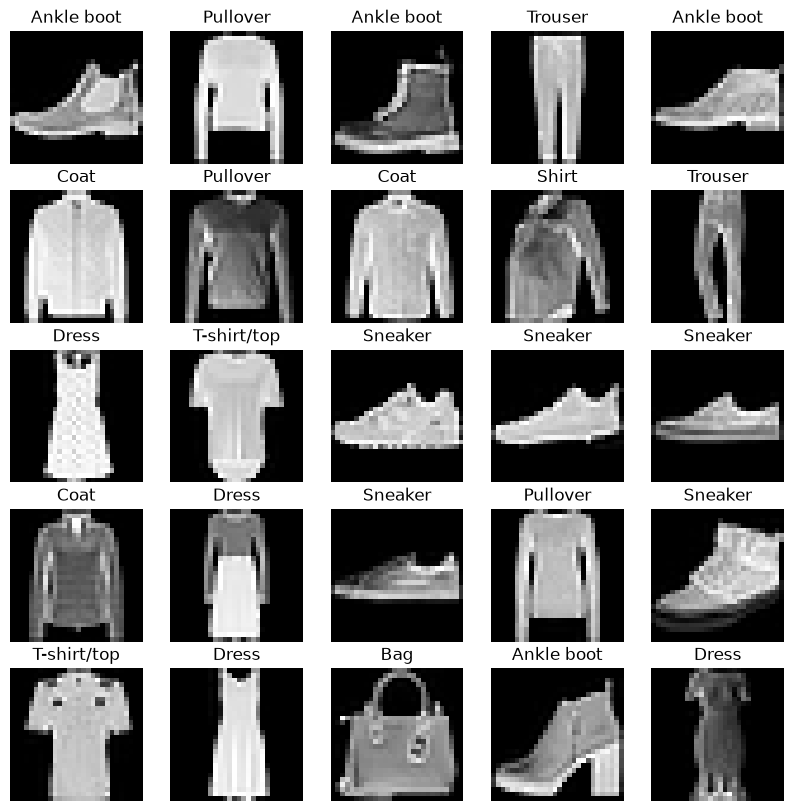

In [9]:
### Now Visualize without random seed.

fig = plt.figure(figsize=(10, 10))

rows, cols = 5, 5

for i in range(1, rows*cols+1):
    random_idx = torch.randint(0, len(train_data), size=[1]).item()

    img, lab = train_data[random_idx]

    fig.add_subplot(rows, cols, i)

    plt.imshow(img.squeeze(), cmap="gray")

    plt.title(class_name[lab])

    plt.axis(False);

In [10]:
train_data, test_data

(Dataset FashionMNIST
     Number of datapoints: 60000
     Root location: data
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset FashionMNIST
     Number of datapoints: 10000
     Root location: data
     Split: Test
     StandardTransform
 Transform: ToTensor())

In [11]:
train_loader = DataLoader(dataset=train_data,
                          batch_size=32,
                          shuffle=True)

test_loader = DataLoader(dataset=test_data,
                         batch_size=32,
                         shuffle=False)


In [12]:
## Let's check out what what we've created 

print(f"DataLoader: {train_loader, test_loader}")

print(f"Length of train dataloader: {len(train_loader)}")
print(f"Length of test dataloader: {len(test_loader)}")

DataLoader: (<torch.utils.data.dataloader.DataLoader object at 0x73addbf36010>, <torch.utils.data.dataloader.DataLoader object at 0x73addbd56e90>)
Length of train dataloader: 1875
Length of test dataloader: 313


In [13]:
## Check out what's inside the training dataloader

train_features_batch, train_labels_batch = next(iter(train_loader))

train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size: torch.Size([1, 28, 28])
Label: Sandal


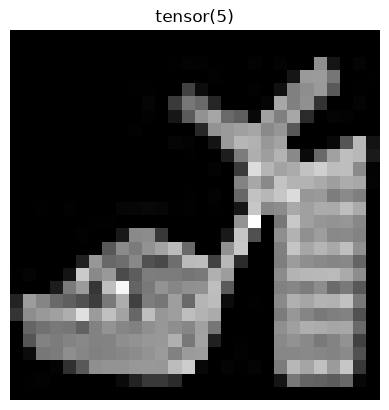

In [14]:
# show a sample 

torch.manual_seed(42)

random_id = torch.randint(0 , len(train_features_batch), size=[1]).item()

img, labels = train_features_batch[random_id], train_labels_batch[random_id]

plt.imshow(img.squeeze(), cmap="gray")

plt.title(labels)

plt.axis(False);

print(f"Image size: {img.shape}")
print(f"Label: {class_name[labels]}")

### Create Model Using nn.Module and nn.Sequential

### Model 0: Build a basline model

##### When starting to build a series of mahine learning modelling experiments, it's best practice to start with a baseline model. A baseline model is a simple model you will try and improve upon with subsequent models/experiments.
##### In other words: start simply and add complexity when necessary.

In [15]:
# Create a flatten layer 

flatten_model = nn.Flatten()

# get a single sample 

x = train_features_batch[0]

# Flatten the sample 

output = flatten_model(x) # perform forward pass

print(f"Shape before flattening: {x.shape} -> [color_channels, height, width]")
print(f"Shape after flattening: {output.shape} -> [color_channels, height*width]")

Shape before flattening: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Shape after flattening: torch.Size([1, 784]) -> [color_channels, height*width]


In [16]:
class FashionMINISTModelV0(nn.Module):
    def __init__(self, 
                 input_shape: int,
                 hidden_units: int,
                 output_shape: int):
        super().__init__()

        self.layer_stack = nn.Sequential(
            nn.Flatten(),

            nn.Linear(in_features=input_shape,
                      out_features=hidden_units),

            nn.Linear(hidden_units, output_shape)

        )

    def forward (self, x):
        return self.layer_stack(x)

In [17]:
torch.manual_seed(42)

model_0 = FashionMINISTModelV0(
    input_shape=784, # 28*28
    hidden_units= 10,
    output_shape=len(class_name)
   
)

In [18]:
# Calculate Accuracy 

# def accuracy_fn(y_true= None, y_preds= None):
#     correct = torch.eq(y_true, y_preds).sum().item()

#     acc = (correct/len(y_preds)) * 100 

#     return acc

In [19]:
lo_fn = nn.CrossEntropyLoss()

op = optim.Adam(params=model_0.parameters(),
                lr=0.001)



## Creating a function to time our experiments 

Machine learning is very experimental.

Two of the main things will often want to track are:
1. Model's performance(loss and accuracy values etc)
2. How fast it runs 

In [20]:
next(model_0.parameters()).device

device(type='cpu')

In [21]:
from timeit import default_timer  as timer 

def print_train_time(start: float,
                     end: float ,
                     device: torch.device = None):
    """Prints difference between start and end time."""

    total_time =  end - start

    print(f"Train time on {device}: {total_time:.3f} seconds")

    return total_time

In [22]:
start_time = timer()

# some code ....

end_time = timer()

print_train_time(start=start_time, end=end_time, device="cpu")

Train time on cpu: 0.000 seconds


1.136299999870971e-05

#### Creating a training loop and training the data in batches.

In [23]:
torch.manual_seed(42)

train_time_start =  timer()


# set the number of epochs 

epochs = 3

# create training and test loop 

for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n_____")

    ## Training 

    train_loss = 0

    # Add a loop to loop through the training batches 

    for batch, (x, y) in enumerate(train_loader):
        model_0.train()

        y_pred = model_0(x)

        # calculate loss per batch
        loss =  lo_fn(y_pred, y)

        train_loss += loss

        op.zero_grad()

        loss.backward()

        op.step()

        if batch % 400 == 0:
            print(f"Looked at {batch * len(x)}/{len(train_loader.dataset)} samples.")


    train_loss /= len(train_loader)


#### Testing 

test_loss, test_acc = 0, 0

model_0.eval()

with torch.inference_mode():
    for X_test, Y_test in test_loader:
        test_pred =  model_0(X_test)

        loss = lo_fn(test_pred, Y_test)

        test_loss += loss

        # calculate accuracy 

        test_acc += accuracy_fn(y_true=Y_test, y_pred=test_pred.argmax(dim=1))

    test_loss /= len(test_loader)

    test_acc /= len(test_loader)


print(f"\nTrain loss: {train_loss: .2f} || Test loss: {test_loss: .2f} || Test Accuracy: {test_acc}")

train_end_time = timer()

total_train_time_model0 = print_train_time(start=train_time_start, end=train_end_time,
                                    device=str(next(model_0.parameters()).device))

      



  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
_____
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Epoch: 1
_____
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Epoch: 2
_____
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.

Train loss:  0.44 || Test loss:  0.49 || Test Accuracy: 82.58785942492013
Train time on cpu: 7.247 seconds


## Make predictions and get Model 0 Results

In [24]:
torch.manual_seed(42)

def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn = torch.nn.Module,
               acc = accuracy_fn,
               device=None):
    """Returns a dictionary containing the results of model predicting on data_loader.."""

    Test_loss, acc = 0, 0

    model.eval()
    with torch.inference_mode():
        for X, Y in tqdm(data_loader):
            X = X.to(device)
            Y = Y.to(device)
            Y_pred = model(X)

            loss = loss_fn(Y_pred, Y)

            Test_loss += loss

            acc += accuracy_fn(y_true=Y,
                               y_pred=Y_pred.argmax(dim=1))

        Test_loss /= len(data_loader)

        acc /= len(data_loader)

    return {"model_name": model.__class__.__name__,
            "model_loss": Test_loss.item(),
            "ModelAccuracy": acc}


model_0_results = eval_model(model=model_0,
                             data_loader=test_loader,
                             loss_fn= lo_fn,
                             acc=accuracy_fn)

model_0_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMINISTModelV0',
 'model_loss': 0.4883008897304535,
 'ModelAccuracy': 82.58785942492013}

In [25]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device: ", device)

Device:  cuda


### Model 1: Building a better model with non-linearity

In [26]:
class FashionMINISTModelV1(nn.Module):
    def __init__(self, input: int,
                  hidden_units: int, 
                  output: int):
        super().__init__()

        self.layer_stack = nn.Sequential(
            nn.Flatten(), 
            nn.Linear(in_features=input, out_features=hidden_units),
            nn.ReLU(),

            nn.Linear(hidden_units, hidden_units*2),
            nn.ReLU(),

            nn.Linear(hidden_units*2, output)

        )

    def forward (self, x: torch.Tensor):
        return self.layer_stack(x)

In [27]:
torch.manual_seed(42)

model_1 = FashionMINISTModelV1(
    input=784,
    hidden_units=10, 
    output=len(class_name)
).to(device)

los_fn = nn.CrossEntropyLoss()
opt = optim.Adam(params=model_1.parameters(), 
                 lr = 0.001)

#### Functionizing Training and Testing/evaluation loops

In [28]:


def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               acc,
               device: torch.device):

    train_loss, train_acc = 0, 0

    model.to(device)
    model.train()

    for batch, (x, y) in enumerate(data_loader):

        x = x.to(device)
        y = y.to(device)

        y_pred = model(x)

        loss = loss_fn(y_pred, y)

        train_loss += loss.item()

        train_acc += acc(
            y_true=y,
            y_pred=torch.softmax(y_pred, dim=1).argmax(dim=1)
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        if batch % 400 == 0:
            print(
                f"Looked at {batch * data_loader.batch_size}/"
                f"{len(data_loader.dataset)} samples."
            )

    train_loss /= len(data_loader)
    train_acc /= len(data_loader)

  

    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")

    print({
        "model_name": model.__class__.__name__,
        "model_loss": train_loss,
        "ModelAccuracy": train_acc
    })


torch.manual_seed(42)

def test_step(model: torch.nn.Module,
              data_loader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              acc=accuracy_fn,
              device: torch.device=device):

    """Returns a dictionary containing the results of model predicting on data_loader."""

    Test_loss, test_acc = 0, 0

    model.to(device)
    model.eval()

    with torch.inference_mode():
        for X, Y in tqdm(data_loader):

            X = X.to(device)
            Y = Y.to(device)

            Y_pred = model(X)

            loss = loss_fn(Y_pred, Y)

            Test_loss += loss.item()

            test_acc += acc(
                y_true=Y,
                y_pred=Y_pred.argmax(dim=1)
            )

        Test_loss /= len(data_loader)
        test_acc /= len(data_loader)

    print(f"Test Loss: {Test_loss:.4f} | Test Accuracy: {test_acc:.2f}%")

    print({
        "model_name": model.__class__.__name__,
        "model_loss": Test_loss,
        "ModelAccuracy": test_acc
    })

In [29]:
torch.manual_seed(42)


model_1 = model_1.to(device)

Gpu_start_time = timer()

epochs = 3

for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n________")

    train_step(
        model=model_1,
        data_loader=train_loader,
        loss_fn=los_fn,
        optimizer=opt,
        acc=accuracy_fn,
        device=device
    )

    test_step(model=model_1,
             data_loader=test_loader,
            loss_fn= los_fn,
            acc=accuracy_fn)

Gpu_end_time = timer()

total_training_time_model1 = Gpu_end_time - Gpu_start_time

print("Training Time in GPU: ", total_training_time_model1)


    

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
________
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train Loss: 0.6946 | Train Accuracy: 75.73%
{'model_name': 'FashionMINISTModelV1', 'model_loss': 0.6945977444489797, 'ModelAccuracy': 75.73}


  0%|          | 0/313 [00:00<?, ?it/s]

Test Loss: 0.5261 | Test Accuracy: 81.55%
{'model_name': 'FashionMINISTModelV1', 'model_loss': 0.5260958742505064, 'ModelAccuracy': 81.54952076677316}
Epoch: 1
________
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train Loss: 0.4788 | Train Accuracy: 83.16%
{'model_name': 'FashionMINISTModelV1', 'model_loss': 0.4787666741927465, 'ModelAccuracy': 83.16}


  0%|          | 0/313 [00:00<?, ?it/s]

Test Loss: 0.5122 | Test Accuracy: 81.83%
{'model_name': 'FashionMINISTModelV1', 'model_loss': 0.5122456274474391, 'ModelAccuracy': 81.82907348242811}
Epoch: 2
________
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train Loss: 0.4502 | Train Accuracy: 84.23%
{'model_name': 'FashionMINISTModelV1', 'model_loss': 0.4502331271926562, 'ModelAccuracy': 84.22666666666667}


  0%|          | 0/313 [00:00<?, ?it/s]

Test Loss: 0.4679 | Test Accuracy: 83.51%
{'model_name': 'FashionMINISTModelV1', 'model_loss': 0.46790553715091926, 'ModelAccuracy': 83.50638977635782}
Training Time in GPU:  10.267413495


## Model 2: Building a Convolutional Neural Network(CNN) 

CNN"s are also known ConvNets.

CNN's are known for their capabilities to find patterns in visual data.



In [30]:
class FashionMINISTModelV2(nn.Module):
    def __init__(self, input: int,
                 hidden_units: int,
                 output: int):

        super().__init__()

        self.ConvModel1 = nn.Sequential(
            nn.Conv2d(
                in_channels=input,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.ConvModel2 = nn.Sequential(
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                in_features=hidden_units*7*7,
                out_features=output
            )
        )

    def forward(self, x):
        x = self.ConvModel1(x)
      
        x = self.ConvModel2(x)
     
        x = self.classifier(x)

        return x

In [31]:
torch.manual_seed(42)

model_2 = FashionMINISTModelV2(
    input=1,
    hidden_units=10,
    output=10
).to(device)

loss_f = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model_2.parameters(),
                    lr = 0.001)


In [32]:
torch.manual_seed(42)

# Create sample batch of random numbers with same size as image batch
images = torch.randn(size=(32, 3, 64, 64)) # [batch_size, color_channels, height, width]
test_image = images[0] # get a single image for testing
print(f"Image batch shape: {images.shape} -> [batch_size, color_channels, height, width]")
print(f"Single image shape: {test_image.shape} -> [color_channels, height, width]") 
print(f"Single image pixel values:\n{test_image}")

Image batch shape: torch.Size([32, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Single image shape: torch.Size([3, 64, 64]) -> [color_channels, height, width]
Single image pixel values:
tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,

### Train with CNN Model 2

In [33]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

Cnn_start_time = timer()

train_lo, train_a = 0, 0

epochs = 3

for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch + 1}")

    model_2.train()

    train_step(model=model_2,
                   data_loader=train_loader,
                   loss_fn=loss_f,
                   optimizer=optimizer,
                   acc=accuracy_fn,
                   device=device )

    test_step(model=model_2,
                 data_loader=test_loader,
                loss_fn= los_fn,
                acc=accuracy_fn,
                device=device)

Cnn_end_time = timer()

total_training_time_model2 = print_train_time(start=Cnn_start_time,
                                           end=Cnn_end_time,
                                           device=device)

print(f"Train time in cpu model: {total_training_time_model2}")

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 1
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train Loss: 0.5345 | Train Accuracy: 80.63%
{'model_name': 'FashionMINISTModelV2', 'model_loss': 0.5345395687659581, 'ModelAccuracy': 80.62666666666667}


  0%|          | 0/313 [00:00<?, ?it/s]

Test Loss: 0.3968 | Test Accuracy: 85.81%
{'model_name': 'FashionMINISTModelV2', 'model_loss': 0.3967698299751495, 'ModelAccuracy': 85.81269968051119}
Epoch: 2
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train Loss: 0.3584 | Train Accuracy: 87.18%
{'model_name': 'FashionMINISTModelV2', 'model_loss': 0.3583763368407885, 'ModelAccuracy': 87.17833333333333}


  0%|          | 0/313 [00:00<?, ?it/s]

Test Loss: 0.3704 | Test Accuracy: 86.32%
{'model_name': 'FashionMINISTModelV2', 'model_loss': 0.3703500756059592, 'ModelAccuracy': 86.32188498402556}
Epoch: 3
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train Loss: 0.3228 | Train Accuracy: 88.45%
{'model_name': 'FashionMINISTModelV2', 'model_loss': 0.32278029148777326, 'ModelAccuracy': 88.455}


  0%|          | 0/313 [00:00<?, ?it/s]

Test Loss: 0.3433 | Test Accuracy: 87.57%
{'model_name': 'FashionMINISTModelV2', 'model_loss': 0.34327376191132364, 'ModelAccuracy': 87.56988817891374}
Train time on cuda: 11.779 seconds
Train time in cpu model: 11.778900528000008


In [34]:
model_2_results = eval_model(model=model_2,
                             data_loader=test_loader,
                             loss_fn=loss_f,
                             acc=accuracy_fn,
                             device = device)

model_2_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMINISTModelV2',
 'model_loss': 0.3432738482952118,
 'ModelAccuracy': 87.56988817891374}

In [35]:
model_1_results = eval_model(model=model_1,
                             data_loader=test_loader,
                             loss_fn=loss_f,
                             acc=accuracy_fn,
                             device=device)

model_1_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMINISTModelV1',
 'model_loss': 0.4679054319858551,
 'ModelAccuracy': 83.50638977635782}

### Compare model results and training time 



In [36]:
compare_results  = pd.DataFrame([model_0_results,
                                 model_1_results,
                                 model_2_results])

compare_results

,model_name,model_loss,ModelAccuracy
0,FashionMINISTModelV0,0.488301,82.587859
1,FashionMINISTModelV1,0.467905,83.506390
2,FashionMINISTModelV2,0.343274,87.569888


In [37]:
compare_results["training_time"] = [total_train_time_model0,
                                    total_training_time_model1, 
                                    total_training_time_model2]

compare_results

,model_name,model_loss,ModelAccuracy,training_time
0,FashionMINISTModelV0,0.488301,82.587859,7.246554
1,FashionMINISTModelV1,0.467905,83.506390,10.267413
2,FashionMINISTModelV2,0.343274,87.569888,11.778901


Text(0, 0.5, 'Model')

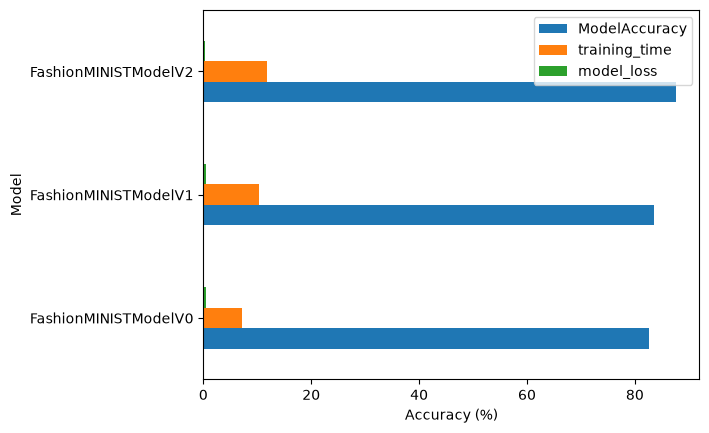

In [38]:
compare_results.set_index("model_name") [["ModelAccuracy", "training_time", "model_loss"]].plot(kind="barh")
plt.xlabel("Accuracy (%)")
plt.ylabel("Model")

In [39]:
def make_predictions(model: torch.nn.Module,
                     data:list,
                     device: torch.device = device):

    pred_probs = []

    model.eval()
    with torch.inference_mode():
        for sample in data:
            sample = torch.unsqueeze(sample, dim=0).to(device=device)

            pred_logit = model(sample)


            pred_prob = torch.softmax(pred_logit.squeeze(), dim=0)

            pred_probs.append(pred_prob.cpu())

    return torch.stack(pred_probs)

In [40]:
import random 

#random.seed(42)

test_samples =[]

test_labels = []

for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample)
    test_labels.append(label)

    test_samples[0].shape

In [41]:
pred_probs = make_predictions(model=model_2,
                              data=test_samples)

pred_probs

tensor([[2.9398e-02, 3.0201e-04, 9.6144e-03, 2.7062e-04, 9.0123e-05, 9.3560e-08,
         2.4686e-01, 1.0468e-07, 7.1345e-01, 1.0512e-05],
        [2.2392e-08, 3.2165e-15, 8.0047e-10, 3.3613e-13, 1.4325e-11, 9.9999e-01,
         1.0028e-08, 1.5161e-06, 9.1041e-06, 2.4640e-07],
        [7.3168e-01, 3.8024e-07, 1.5369e-05, 8.5041e-05, 2.8706e-07, 3.1081e-09,
         2.6821e-01, 4.9215e-13, 7.0800e-06, 2.0156e-10],
        [1.3388e-07, 1.2262e-10, 1.8585e-09, 1.7812e-08, 7.4769e-10, 2.0507e-04,
         1.9780e-08, 9.9973e-01, 3.0501e-05, 3.7517e-05],
        [7.3168e-06, 1.9393e-08, 2.0912e-09, 2.4939e-09, 2.2839e-10, 9.9588e-01,
         1.3089e-06, 3.7137e-04, 6.5030e-05, 3.6715e-03],
        [1.1969e-01, 1.6025e-03, 2.9827e-01, 1.7285e-01, 3.6872e-01, 4.5600e-07,
         2.4487e-02, 1.2044e-05, 1.4325e-02, 3.5697e-05],
        [1.4737e-06, 4.9418e-12, 3.3338e-09, 1.2471e-08, 3.9905e-10, 9.9290e-01,
         3.9391e-07, 6.7794e-03, 1.2547e-04, 1.9178e-04],
        [1.8871e-07, 9.9998

In [42]:
pred_classes = pred_probs.argmax(dim=1)

pred_classes

tensor([8, 5, 0, 7, 5, 4, 5, 1, 2])

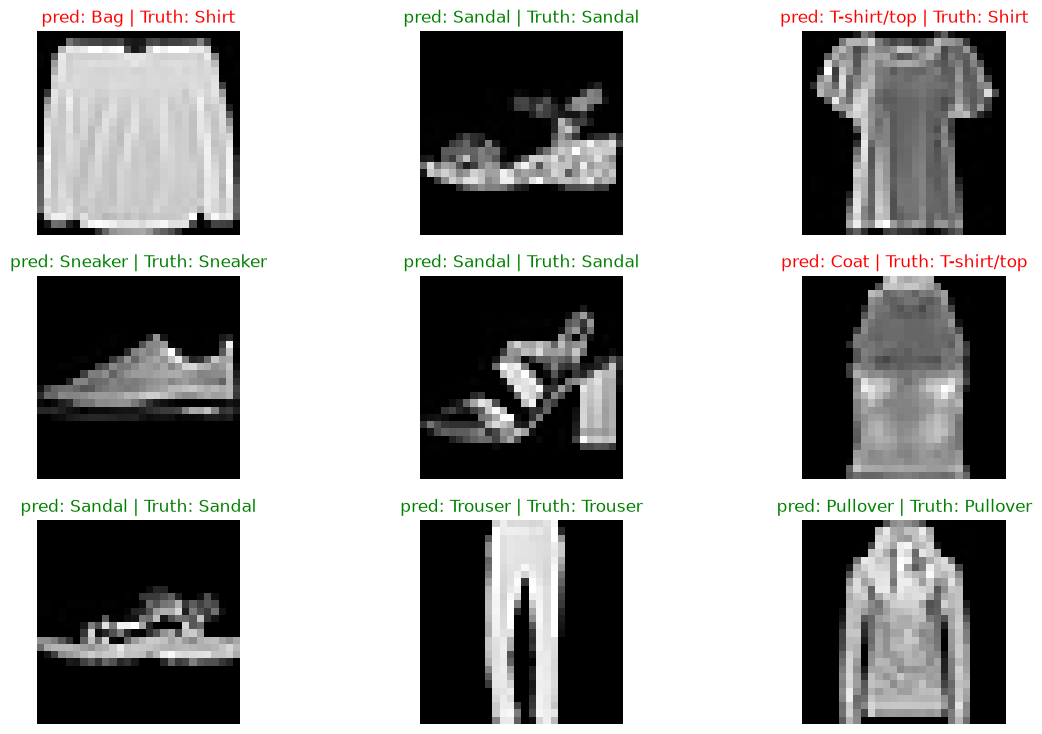

In [43]:
plt.figure(figsize=(14,9))
nrows = 3
ncols = 3

for i, sample in enumerate(test_samples):
    plt.subplot(nrows, ncols, i+1)

    plt.imshow(sample.squeeze(), cmap="gray")

    pred_label = class_name[pred_classes[i]]
    real_label = class_name[test_labels[i]]

    title_text = f"pred: {pred_label} | Truth: {real_label}"

    if pred_label == real_label:
        plt.title(title_text, c="g")

    else:
        plt.title(title_text, c="r")

    plt.axis(False)

### Making  a confusion matrix matrix for Classification problem.

1. Make predictions with our trained model on the test dataset 
2. Make a confusion matrix `torchmetrics.ConfusionMetrics`
3. plot the confusion matrix using `mlxtend.plotting.plot_confusion_matrix()`

In [44]:
y_preds = []

model_2.eval()
with torch.inference_mode():
    for x_test, y_test in tqdm(test_loader, desc="Making predictions.."):
        x_test, y_test = x_test.to(device), y_test.to(device)

        y_logits = model_2(x_test)
    # Turn predictions from logits -> prediction probabilities -> prediction labels
        y_pred = torch.softmax(y_logits, dim=0).argmax(dim=1)

    # Logits → probabilities → predicted class labels
        # y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)

        y_preds.append(y_pred.cpu())


#print(y_preds)
y_pred_tensor = torch.cat(y_preds)

y_pred_tensor[:10]
        

Making predictions..:   0%|          | 0/313 [00:00<?, ?it/s]

tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])

In [45]:
# See if torchmetrics exists, if not, install it
try:
    import torchmetrics, mlxtend
    print(f"mlxtend version: {mlxtend.__version__}")
    assert int(mlxtend.__version__.split(".")[1]) >= 19, "mlxtend verison should be 0.19.0 or higher"
except:
    %pip install -q torchmetrics -U mlxtend 
    import torchmetrics, mlxtend
    print(f"mlxtend version: {mlxtend.__version__}")

mlxtend version: 0.25.0


## setup  confusion instance and compare predictions to targets 



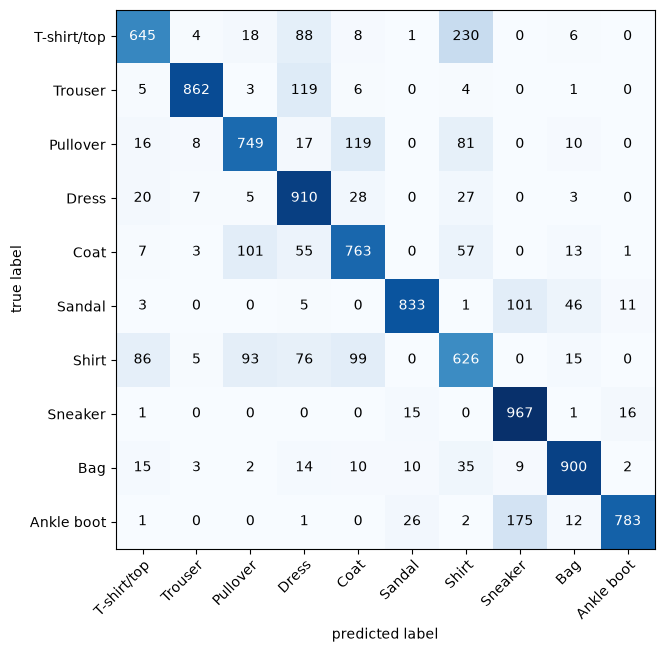

In [46]:
confmat = ConfusionMatrix(num_classes=len(class_name), task="multiclass")

confmat_tensor = confmat(preds=y_pred_tensor,
                         target=test_data.targets)


fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(), #matplotlib likes working with numpy
    class_names= class_name,
    figsize=(10, 7)
)

## Save and load best performing Model

In [47]:
model_path = Path("models")

model_path.mkdir(parents=True, exist_ok=True)

Model_Name = "03_pytorch_classification_CNN_model.pt"

MODEL_SAVE_PATH = model_path / Model_Name

torch.save(obj= model_2.state_dict(),
           f=MODEL_SAVE_PATH)



In [48]:
torch.manual_seed(42)

loaded_model2 = FashionMINISTModelV2(input=1,
                                    hidden_units=10,
                                    output=len(class_name))

loaded_model2.load_state_dict(torch.load(f= MODEL_SAVE_PATH))

loaded_model2.to(device=device)

FashionMINISTModelV2(
  (ConvModel1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (ConvModel2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [49]:
model_2_results

{'model_name': 'FashionMINISTModelV2',
 'model_loss': 0.3432738482952118,
 'ModelAccuracy': 87.56988817891374}

In [50]:
loaded_model2_results = eval_model(model=loaded_model2,
                                   data_loader=test_loader,
                                   loss_fn=loss_f,
                                   acc=accuracy_fn,
                                   device=device)

loaded_model2_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMINISTModelV2',
 'model_loss': 0.3432738482952118,
 'ModelAccuracy': 87.56988817891374}